# 2일차 16코드 Jupyter 리뷰 — src/16_preprocess_compare.py

교재: `2일차 16코드 Jupyter로 코드 리뷰 방법.md`

- 이 노트북은 **프로젝트 최상위 폴더**에 둡니다.
- 위에서 아래로 `Shift+Enter`로 실행하고, 최종 확인은 **Kernel 재시작 후 전체 실행**.
- 단축키: `Esc`→`B`/`A` 셀 추가 · `Esc`→`Y`/`M` 코드/Markdown · `Esc`→`D` `D` 삭제 · `Esc`→`0` `0` 커널 재시작

## 오늘 완성할 파일과 입력 데이터

```text
subject9_machinevision/
├── samples/
│   └── day02/
│       ├── cap_on_reference.jpg       ← 1일차에 만든 병뚜껑 ROI 기준 이미지
│       └── low_contrast.jpg           ← 비교 입력(없으면 코드로 생성)
├── src/
│   └── 16_preprocess_compare.py       ← 기존 전체 실행용 코드
└── outputs/
    └── day02/
        └── compare/
            └── preprocess_compare.png ← 최종 2×2 비교 결과
```

**실습 시작 전:** VS Code에서 `subject9_machinevision` 프로젝트를 열고, 1일차부터 사용한 WSL2 가상환경을 **Jupyter Kernel**로 선택합니다. 필요할 때만 Notebook 셀에서 `%pip install matplotlib ipykernel`을 실행하고 **Kernel Restart**합니다. 이미 설치된 OpenCV와 NumPy는 다시 설치하지 않습니다.

**이번 수정의 핵심:** VS Code 탐색기에 `samples/day02/low_contrast.jpg`가 존재해도 Jupyter Kernel의 현재 작업 폴더가 다르면 `cv2.imread("samples/day02/low_contrast.jpg")`는 실패할 수 있습니다. **STEP 2에서 프로젝트의 실제 위치를 찾고, STEP 3에서 모든 경로를 절대경로로 설정**합니다. STEP 5에서는 파일이 없을 때와 파일은 있지만 읽기에 실패했을 때를 구별합니다. 파일이 있는 상태에서 데이터를 덮어쓰지 않습니다.

> **중요:** 본 자료는 Markdown 교재입니다. 설명과 표를 한꺼번에 Jupyter 코드 셀에 붙여넣지 마세요. 각 STEP의 `python` 코드 블록만 별도 셀에서 위에서 아래로 실행합니다. 기존 코드와 같은 계산 결과를 만들지만, 학습 목적의 통계·검증용 셀을 추가했습니다.

**실행 원칙:** 각 STEP의 `python` 블록을 Jupyter Code Cell로 옮깁니다. 변수는 다음 셀에서 이어서 사용합니다. 설정이나 입력을 수정했다면 **영향받는 뒤쪽 STEP을 모두 다시 실행**합니다. 검증할 때는 **Kernel Restart → Run All**로 재현성을 확인합니다. STEP 53의 원본 스크립트 별도 실행은 선택 항목입니다.

## 1. 전체 흐름

```text
[1일차에서 준비한 기준 ROI]
        ↓
[BLOCK 1 — INPUT / 입력 확인]
low_contrast.jpg 읽기 → 없으면 기준 ROI로 생성
        ↓
[BLOCK 2 — INPUT ANALYSIS / Gray 픽셀 분석]
BGR → Gray → 픽셀·Histogram 확인
        ↓
[BLOCK 3 — PROCESS A / 전처리 없음]
Gray → Otsu → Binary 원리 검증
        ↓
[BLOCK 4 — PROCESS B / Gaussian]
Gray → Gaussian → Otsu → Binary 확인
        ↓
[BLOCK 5 — PROCESS C / CLAHE]
Gray → CLAHE → Otsu → Binary 확인
        ↓
[BLOCK 6 — COMPARE / 결과 수치·시각 비교]
Otsu 임계값·흰색 픽셀 비율·세 결과 비교
        ↓
[BLOCK 7 — DISPLAY / make_view 함수 이해]
Resize → 채널 변환 → 제목 표시 → 함수 정의
        ↓
[BLOCK 8 — COMPOSE / 2×2 화면 조립]
hconcat → vconcat → 비교 이미지 확인
        ↓
[BLOCK 9 — OUTPUT·QA / 저장·검증·원본 연결]
preprocess_compare.png 저장 → 재읽기 → 원본 .py 실행
        ↓
[3일차 연계]
동일한 ROI → Otsu → Morphology → Contour → 측정·판정
```

### 블록별 핵심 질문

| 블록 | 구분 | 무엇을 직접 증명하나요? |
|---|---|---|
| 1 | 입력·예외 처리 | 이미지가 없을 때 기준 ROI에서 동일한 비교 입력을 만드는가? |
| 2 | Gray 분석 | 컬러 픽셀값이 Gray 픽셀값으로 어떻게 변하는가? |
| 3 | Original + Otsu | 임계값을 경계로 0과 255가 정확히 어떻게 결정되는가? |
| 4 | Gaussian + Otsu | 주변 픽셀을 부드럽게 만든 후 이진화 결과는 어떻게 바뀌는가? |
| 5 | CLAHE + Otsu | 지역 대비를 조정한 후 이진화 결과는 어떻게 바뀌는가? |
| 6 | 비교·해석 | 임계값과 흰색 면적만으로 ‘개선’을 단정할 수 있는가? |
| 7 | 결과 표시 함수 | 왜 Gray를 BGR로 바꾸고, Binary는 다르게 Resize하는가? |
| 8 | 비교 화면 조립 | 네 장의 이미지를 어떤 순서로 합치는가? |
| 9 | 저장·검증·통합 | 원본 `.py`와 같은 출력 구조로 정상 저장되는가? |

---

# BLOCK 1 — 이미지 입력과 오류 처리 (Input + Validation)

**실제 문제 사례:** VS Code 탐색기에는 `samples/day02/low_contrast.jpg`가 보이지만 Jupyter에서 `이미지 읽기 성공: False`가 나왔습니다. 이 현상은 **파일이 없어서가 아니라 Kernel의 작업 기준 위치가 달라져 상대경로가 틀렸을 가능성**이 큽니다. 이번 실습에서는 파일 존재 여부와 절대경로를 먼저 확인하여 이 문제를 해결합니다.

### 의사코드

```text
STEP 1. OpenCV, NumPy, Matplotlib을 가져오고 Jupyter 커널을 확인한다.
STEP 2. 실제 프로젝트 폴더를 찾는다. (자동 탐색 실패 시 경로 직접 지정)
STEP 3. project_root를 이용해 기준 이미지·저대비 이미지·출력 폴더의 절대경로를 만든다.
STEP 4. 결과 저장 폴더를 준비한다.
STEP 5. low_contrast.jpg가 있으면 읽는다. 파일은 있는데 읽지 못하면 오류를 발생시킨다.
STEP 6. 저대비 이미지가 없다면 cap_on_reference.jpg를 읽는다.
STEP 7. 기준 이미지로 저대비 이미지를 만들고 저장한다. 기존 파일은 덮어쓰지 않는다.
STEP 8. image가 실제 3채널 uint8 배열인지 확인한다.
STEP 9. 입력 이미지가 제대로 보이는지 화면에서 확인한다.
```

## STEP 1. 라이브러리를 가져옵니다

In [1]:
# BLOCK 1 / STEP 1 — 라이브러리 및 Jupyter Kernel 확인
from pathlib import Path
import sys
import cv2
import numpy as np                 # Jupyter 분석용
import matplotlib.pyplot as plt   # Jupyter 시각화용

print("현재 Python:", sys.executable)
print("OpenCV 버전:", cv2.__version__)

현재 Python: /home/user1/ai_vision/subject9_machinevision/.venv/bin/python
OpenCV 버전: 5.0.0


`Path`는 경로, OpenCV는 영상처리, NumPy는 픽셀 배열 검증, Matplotlib은 이미지와 Histogram 출력에 사용합니다. `sys.executable`에 표시된 Python이 수업에서 사용하는 **WSL2 프로젝트 가상환경**인지 확인합니다. `ModuleNotFoundError`가 발생한 **라이브러리만** `%pip install matplotlib`과 같은 형태로 설치한 후 커널을 다시 시작하세요.

## STEP 2. 현재 작업 폴더를 확인합니다

In [2]:
# STEP 2 — 프로젝트의 실제 위치 찾기 (경로 문제 핵심 수정)
# Jupyter가 프로젝트 내부, notebooks/ 하위 폴더, 다른 작업 폴더에서
# 실행되더라도 프로젝트를 찾을 수 있게 합니다.

current_dir = Path.cwd().resolve()
candidates = [
    current_dir,
    *current_dir.parents,
    Path.home() / "ai_vision" / "subject9_machinevision",
    Path.home() / "subject9_machinevision",
]

project_root = None
for folder in candidates:
    if (folder / "samples/day02/cap_on_reference.jpg").is_file():
        project_root = folder.resolve()
        break

print("Jupyter 현재 작업 폴더:", current_dir)
print("찾은 프로젝트 폴더:", project_root)

if project_root is None:
    raise FileNotFoundError(
        "프로젝트 위치를 자동으로 찾지 못했습니다. "
        "Jupyter가 WSL2 가상환경에서 실행 중인지 확인하고, "
        "STEP 2의 project_root를 실제 프로젝트 절대경로로 지정하세요. "
        "예: project_root = Path.home() / 'ai_vision' / 'subject9_machinevision'"
    )

Jupyter 현재 작업 폴더: /home/user1/ai_vision/subject9_machinevision
찾은 프로젝트 폴더: /home/user1/ai_vision/subject9_machinevision


**이 STEP은 원본 `.py`에는 없는 Jupyter 경로 문제 예방 코드입니다.** 실제 프로젝트의 `cap_on_reference.jpg`가 있는 폴더를 기준으로 찾습니다. 프로젝트가 별도 위치라면 자동 탐색을 대신하여 `project_root = Path("/실제/프로젝트/절대경로")`로 직접 지정하세요. 예시 경로가 내 PC에 존재한다고 가정하지 마세요.

- `Path.cwd()`는 Jupyter Kernel의 **현재 실행 기준 위치**입니다. VS Code 탐색기 위치와 다를 수 있습니다.
- `project_root`가 `None`이면 파일을 읽기 전에 즉시 중단합니다. 잘못된 위치에 새 `samples` 폴더를 만드는 실수를 방지합니다.

## STEP 3. 입력 파일 경로 세 개를 정합니다

In [3]:
# STEP 3 — 절대경로로 입력·출력 파일 지정 (원본 .py와 같은 실습 데이터)
reference_path = project_root / "samples/day02/cap_on_reference.jpg"
low_contrast_path = project_root / "samples/day02/low_contrast.jpg"
output_dir = project_root / "outputs/day02/compare"

print("기준 ROI 경로:", reference_path)
print("저대비 이미지 경로:", low_contrast_path)
print("저대비 이미지 존재:", low_contrast_path.is_file())
print("결과 저장 폴더:", output_dir)

기준 ROI 경로: /home/user1/ai_vision/subject9_machinevision/samples/day02/cap_on_reference.jpg
저대비 이미지 경로: /home/user1/ai_vision/subject9_machinevision/samples/day02/low_contrast.jpg
저대비 이미지 존재: True
결과 저장 폴더: /home/user1/ai_vision/subject9_machinevision/outputs/day02/compare


프로젝트의 실제 위치인 `project_root`부터 경로를 이어 붙입니다. 따라서 Jupyter가 어느 폴더에서 시작했든 파일 경로가 고정됩니다. `low_contrast.jpg`가 이미 있다면 **`저대비 이미지 존재: True`**가 표시되어야 합니다. 없을 경우에는 STEP 6~7에서 기준 ROI를 이용해 생성합니다.

## STEP 4. 결과를 저장할 폴더를 생성합니다

In [4]:
# STEP 4 — 결과 폴더 생성
output_dir.mkdir(parents=True, exist_ok=True)
print("결과 폴더 존재:", output_dir.is_dir())

결과 폴더 존재: True


- `parents=True`: 중간 경로도 필요하면 함께 생성합니다.
- `exist_ok=True`: 이미 존재하는 폴더를 유지합니다.
- 이 STEP은 **출력 폴더만** 만들며 입력 이미지 파일에는 영향을 주지 않습니다.

## STEP 5. 저대비 이미지를 읽습니다

In [5]:
# STEP 5 — 파일 존재 여부와 실제 이미지 읽기 성공을 구분
# 파일이 존재한다면 읽고, 읽기 실패 시 원인을 확인하도록 중단합니다.
# 파일이 없는 경우에만 STEP 6~7에서 새로 만듭니다.

image = None
if low_contrast_path.is_file():
    image = cv2.imread(str(low_contrast_path))
    if image is None:
        raise OSError(
            f"파일은 존재하지만 OpenCV가 읽지 못했습니다: {low_contrast_path}. "
            "파일 손상·권한·형식을 확인하세요."
        )
    print("이미지 읽기 성공: True")
    print("읽은 파일:", low_contrast_path)
else:
    print("이미지 파일이 아직 없습니다. STEP 6~7에서 생성합니다.")

이미지 읽기 성공: True
읽은 파일: /home/user1/ai_vision/subject9_machinevision/samples/day02/low_contrast.jpg


**문제가 발생했던 부분을 수정한 STEP입니다.** 파일이 이미 있는 상황에서 `False`가 나오던 문제는 대부분 잘못된 상대경로 기준 때문에 발생합니다. 이번에는 **절대경로**를 사용합니다. 파일이 없으면 `cv2.imread`를 시도하지 않아 불필요한 OpenCV 경고도 줄어듭니다. 파일은 있지만 읽을 수 없다면 **없는 것으로 취급해 덮어쓰지 않고**, 실제 문제를 확인하도록 오류를 발생시킵니다.

## STEP 6. 이미지가 없다면 기준 ROI를 읽습니다

In [6]:
# STEP 6 — 저대비 이미지가 없을 경우에만 기준 ROI 읽기
if image is None:
    print("저대비 이미지가 없어 기준 ROI로 생성합니다.")
    reference = cv2.imread(str(reference_path))
    if reference is None:
        raise FileNotFoundError(
            f"기준 ROI 이미지를 읽지 못했습니다: {reference_path}"
        )
    print("기준 ROI Shape:", reference.shape)
else:
    print("이미 존재하는 low_contrast.jpg를 그대로 사용합니다.")

이미 존재하는 low_contrast.jpg를 그대로 사용합니다.


이미 STEP 5에서 파일을 읽었다면 `reference`는 새로 읽지 않습니다. 따라서 `reference` 변수가 없는 것은 **정상 경로에서 문제가 아닙니다**. `image is None`일 때에만 다음 STEP 7에서 `reference`를 사용합니다.

## STEP 7. 기준 이미지로 저대비 이미지를 생성하고 저장합니다

In [7]:
# STEP 7 — 저대비 이미지가 없을 때만 생성·저장
if image is None:
    image = cv2.convertScaleAbs(reference, alpha=0.35, beta=80)
    created = cv2.imwrite(str(low_contrast_path), image)
    if not created:
        raise IOError(f"저대비 이미지 저장 실패: {low_contrast_path}")
    print("새 저대비 이미지 생성:", low_contrast_path)
else:
    print("기존 이미지 유지: 새 파일을 생성하지 않았습니다.")

기존 이미지 유지: 새 파일을 생성하지 않았습니다.


이 코드는 원본 16번의 **`low_contrast.jpg`가 없을 때만 생성**하는 처리와 일치합니다. `alpha=0.35`는 픽셀 간 차이를 작게 만들고, `beta=80`은 모든 픽셀값을 이동시킵니다. `cv2.convertScaleAbs`는 절댓값 후 `uint8` 변환을 수행합니다. 이 입력과 설정에서는 값이 양수이므로 절댓값에 따른 별도 왜곡은 없습니다. 이미 있던 파일은 덮어쓰지 않습니다.

## STEP 8. 최종 입력 배열의 크기와 픽셀값을 확인합니다

In [8]:
# STEP 8 — 최종 입력 배열 검사: 문제를 조기에 발견
if image is None or image.size == 0:
    raise ValueError("이미지 배열이 비어 있습니다. STEP 2~7을 확인하세요.")
if image.ndim != 3 or image.shape[2] != 3:
    raise ValueError(f"3채널 BGR 이미지가 필요합니다: shape={image.shape}")
if image.dtype != np.uint8:
    raise ValueError(f"8비트 이미지가 필요합니다: dtype={image.dtype}")

print("image 자료형:", type(image))
print("image Shape:", image.shape)
print("image Dtype:", image.dtype)
print("첫 픽셀(BGR):", image[0, 0])

image 자료형: <class 'numpy.ndarray'>
image Shape: (198, 213, 3)
image Dtype: uint8
첫 픽셀(BGR): [147 145 145]


`shape`는 `(세로, 가로, 3)`, `dtype`은 `uint8`이어야 합니다. 파일 경로 문제가 없어도 형식이 잘못되면 이후 `cv2.cvtColor`가 실패할 수 있으므로 입력에서 확인합니다.

## STEP 9. 저대비 입력 이미지를 눈으로 확인합니다

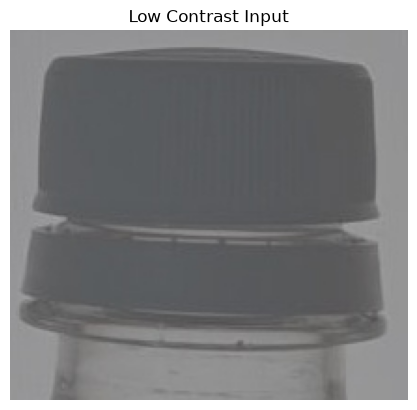

In [9]:
### STEP 9 — [Jupyter 추가] 컬러 이미지 출력
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title("Low Contrast Input")
plt.axis("off")
plt.show()

OpenCV는 BGR로 읽지만 Matplotlib은 RGB 순서로 표시하므로 `cv2.COLOR_BGR2RGB`를 사용합니다. **여기서는 화면 표시만 바꾸며 `image` 원본 배열을 변경하지 않습니다.**

**확인 질문:** 병뚜껑과 배경이 얼마나 구분되나요? 색상보다 밝기의 차이만으로도 잘 구분할 수 있을까요?

---

# BLOCK 2 — Gray 변환과 픽셀값 검증 (Input Analysis)

### 의사코드

```text
1. BGR 컬러 이미지를 Gray 이미지로 변환한다.
2. 채널 수와 데이터 크기가 어떻게 변했는지 본다.
3. 한 픽셀의 BGR 값으로 Gray 값을 대략 계산해본다.
4. 전체 Gray 이미지와 밝기 분포를 눈으로 확인한다.
```

## STEP 10. BGR 이미지를 Gray로 변환합니다

In [10]:
### BLOCK 2 / STEP 10 — 원본 .py의 Gray 처리
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

`cv2.COLOR_BGR2GRAY`는 BGR 세 채널을 밝기 정보 한 채널로 바꿉니다. 이 작업은 **3일차에서 Otsu를 다시 사용할 때도 동일하게 등장**합니다.

## STEP 11. Gray 변환 전후 배열 크기를 확인합니다

In [11]:
### STEP 11 — 채널 수 변화 확인
print("BGR Shape:", image.shape)
print("Gray Shape:", gray.shape)
print("Gray Dtype:", gray.dtype)

BGR Shape: (198, 213, 3)
Gray Shape: (198, 213)
Gray Dtype: uint8


`image.shape`에 있던 마지막 채널 차원 `3`이 `gray.shape`에서는 사라지는지 확인합니다. 원본과 Gray는 같은 가로·세로 픽셀 개수를 갖습니다.

## STEP 12. Gray의 한 픽셀값을 직접 계산해 봅니다

In [12]:
### STEP 12 — [Jupyter 추가] Gray 수치 검증
b, g, r = map(int, image[0, 0])
gray_approx = 0.114 * b + 0.587 * g + 0.299 * r
print("BGR:", (b, g, r))
print("계산한 Gray(근사):", gray_approx)
print("OpenCV Gray:", int(gray[0, 0]))

BGR: (147, 145, 145)
계산한 Gray(근사): 145.22799999999998
OpenCV Gray: 145


OpenCV의 일반적인 8비트 BGR→Gray 변환은 밝기에 대한 채널별 가중치를 사용합니다. 결과가 완전히 똑같지 않을 수 있는 것은 **정수 반올림·내부 계산 방식의 차이** 때문입니다. 픽셀 하나를 근사 계산해 보는 것은 원본 `.py`에 없는 이해용 실험입니다.

## STEP 13. Gray 이미지를 화면에 표시합니다

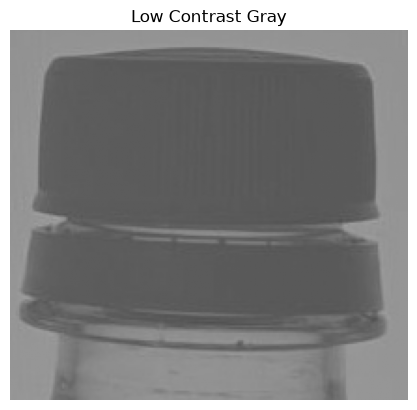

In [13]:
### STEP 13 — [Jupyter 추가] 단일 채널 출력
plt.imshow(gray, cmap="gray", vmin=0, vmax=255)
plt.title("Low Contrast Gray")
plt.axis("off")
plt.show()

`cmap="gray"`는 **숫자 하나로 된 배열을 회색조로 그려주는 표시 옵션**입니다. 배열을 다시 변환하는 것은 아닙니다.

## STEP 14. Histogram으로 밝기값의 분포를 확인합니다

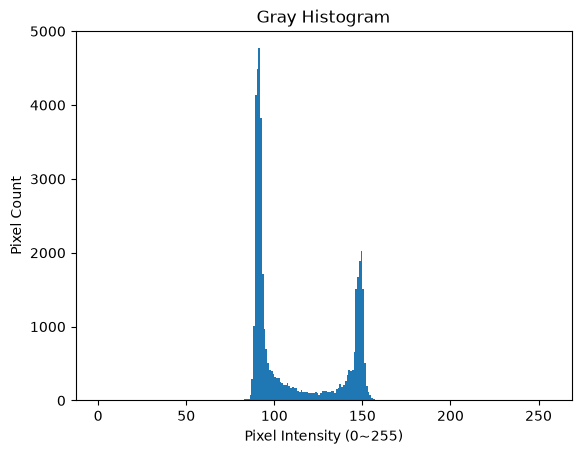

In [14]:
### STEP 14 — [Jupyter 추가] 밝기 분포
plt.hist(gray.ravel(), bins=256, range=(0, 256))
plt.title("Gray Histogram")
plt.xlabel("Pixel Intensity (0~255)")
plt.ylabel("Pixel Count")
plt.show()

`gray.ravel()`은 2차원 픽셀을 1차원으로 펼쳐 Histogram에 사용합니다. 밝기값이 좁은 구간에 몰려 있으면 저대비 가능성을 의심할 수 있지만, Histogram만으로 병뚜껑 분리 성능이 좋고 나쁨을 단정하지는 않습니다.

---

# BLOCK 3 — 전처리 없이 Otsu 검증 (Process A)

### 의사코드

```text
1. 이진화의 원리를 단순한 숫자로 먼저 확인한다.
2. Gray 이미지에 Otsu를 적용한다.
3. Otsu가 선택한 임계값과 Binary 픽셀값을 출력한다.
4. 실제 픽셀 하나가 흰색 또는 검정이 된 이유를 검증한다.
5. Gray와 Binary를 나란히 보며 병뚜껑 분리 상태를 확인한다.
```

## STEP 15. 임계값이 어떻게 0과 255를 만드는지 먼저 확인합니다

In [15]:
### BLOCK 3 / STEP 15 — [Jupyter 추가] Threshold 최소 예제
pixels = np.array([[60, 100, 130, 180]], dtype=np.uint8)
_, sample_binary = cv2.threshold(pixels, 120, 255, cv2.THRESH_BINARY_INV)
print("입력 픽셀:", pixels[0].tolist())
print("출력 픽셀:", sample_binary[0].tolist())

입력 픽셀: [60, 100, 130, 180]
출력 픽셀: [255, 255, 0, 0]


**예상 출력:** 입력 `[60, 100, 130, 180]` → 출력 `[255, 255, 0, 0]`. `THRESH_BINARY_INV`에서는 기준값 **이하**를 흰색(255), **초과**를 검정(0)으로 만듭니다. 병뚜껑이 배경보다 어두운 경우 병뚜껑을 흰색 객체로 만들기 위해 이 방향을 사용합니다.

## STEP 16. 원본 Gray에 Otsu를 적용합니다

In [16]:
### STEP 16 — 원본 .py의 첫 번째 Otsu
original_value, original_otsu = cv2.threshold(
    gray, 0, 255,
    cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU,
)

- 입력 `gray`: 전처리를 추가로 하지 않은 Gray 이미지입니다.
- `0`: Otsu를 사용하므로 **자동 결정할 임계값의 자리**입니다(고정 임계값 0을 사용한다는 뜻이 아닙니다).
- `255`: Binary에서 흰색으로 지정할 값입니다.
- 결과 `original_value`: Otsu가 계산해 반환한 임계값입니다.
- 결과 `original_otsu`: 해당 임계값을 적용한 흑백 이미지입니다.

## STEP 17. Otsu 임계값과 Binary 고유값을 확인합니다

In [17]:
### STEP 17 — 숫자로 확인
print("Original Otsu Threshold:", original_value)
print("Binary Shape:", original_otsu.shape)
print("Binary 고유 픽셀값:", np.unique(original_otsu))

Original Otsu Threshold: 118.0
Binary Shape: (198, 213)
Binary 고유 픽셀값: [  0 255]


`np.unique(original_otsu)`는 일반적으로 `[0 255]` 또는 객체가 전부 한쪽에 분류되면 한 가지 값만 나옵니다. **흰색과 검정이 실제로 어떤 숫자인지** 직접 확인하는 단계입니다.

## STEP 18. 픽셀 하나가 어떤 기준으로 나뉘었는지 검증합니다

In [18]:
### STEP 18 — [Jupyter 추가] 임의의 한 픽셀 판정 확인
h, w = gray.shape
y, x = h // 2, w // 2
print("검사 픽셀 위치(x, y):", (x, y))
print("Gray 값:", int(gray[y, x]))
print("임계값:", original_value)
print("예상 Binary:", 255 if gray[y, x] <= original_value else 0)
print("실제 Binary:", int(original_otsu[y, x]))

검사 픽셀 위치(x, y): (106, 99)
Gray 값: 90
임계값: 118.0
예상 Binary: 255
실제 Binary: 255


여기서 **예상 Binary와 실제 Binary가 같아야** 합니다. 두 숫자가 일치한다는 사실은 Threshold 코드의 동작을 검증하지만, 그 위치가 실제 병뚜껑인지까지 증명하는 것은 아닙니다.

## STEP 19. Gray와 Otsu 결과를 나란히 표시합니다

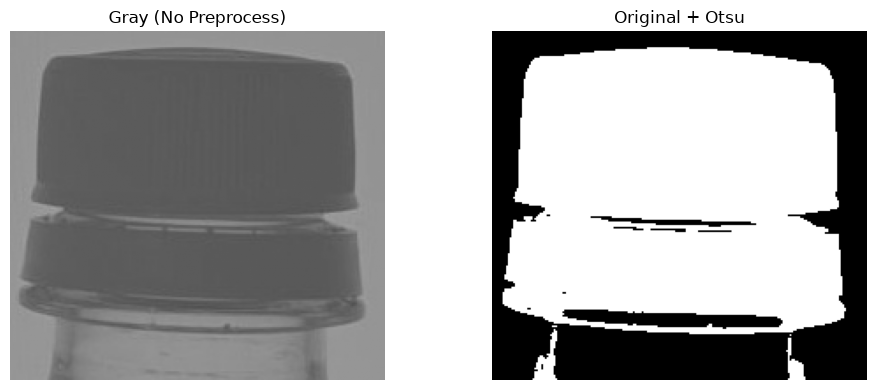

In [19]:
### STEP 19 — [Jupyter 추가] 결과 비교
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(gray, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Gray (No Preprocess)")
axes[1].imshow(original_otsu, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("Original + Otsu")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

**결과 확인:** 어두운 병뚜껑이 흰색으로, 상대적으로 밝은 배경이 검정으로 나뉘나요? 병뚜껑이 끊기거나 배경에 흰색 점이 생겼나요?

---

# BLOCK 4 — Gaussian Blur 후 Otsu 검증 (Process B)

### 의사코드

```text
1. Gray 이미지를 5×5 Gaussian Kernel로 부드럽게 만든다.
2. 픽셀 변화량과 전후 화면을 확인한다.
3. Gaussian 결과에 Otsu를 적용한다.
4. 전처리 없는 Otsu와 이진화 결과가 다른지 확인한다.
```

## STEP 20. Gaussian Blur를 적용합니다

In [20]:
### BLOCK 4 / STEP 20 — 원본 .py의 Gaussian 단계
gaussian = cv2.GaussianBlur(gray, (5, 5), 0)

`(5, 5)`는 주변을 계산할 Kernel의 가로·세로 크기이며, `0`은 OpenCV가 Kernel에 맞는 시그마를 자동으로 선택하도록 하는 설정입니다. 주변 픽셀을 평균적으로 부드럽게 만들어 작은 Noise를 줄이지만 **경계도 함께 흐릴 수 있습니다.**

## STEP 21. 실제 픽셀값이 얼마나 바뀌었는지 확인합니다

In [21]:
### STEP 21 — [Jupyter 추가] 변화량 측정
pixel_change = cv2.absdiff(gray, gaussian)
print("Gaussian Shape:", gaussian.shape)
print("평균 절댓값 변화량:", float(pixel_change.mean()))
print("최대 픽셀 변화량:", int(pixel_change.max()))

Gaussian Shape: (198, 213)
평균 절댓값 변화량: 1.2836581780243752
최대 픽셀 변화량: 18


`cv2.absdiff()`는 같은 위치의 Gray와 Gaussian 픽셀을 비교해 절댓값 차이를 구합니다. **변화량이 크다고 무조건 개선이 잘된 것은 아닙니다.**

## STEP 22. Gaussian 전후 이미지를 비교합니다

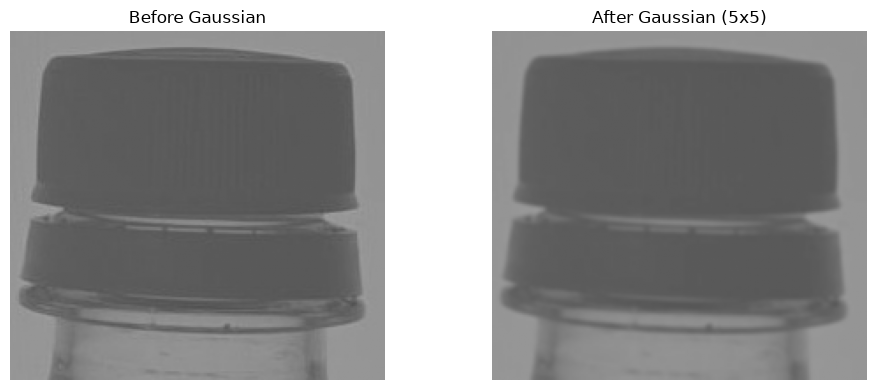

In [22]:
### STEP 22 — [Jupyter 추가] Blur 전후 시각화
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(gray, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Before Gaussian")
axes[1].imshow(gaussian, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("After Gaussian (5x5)")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

**확인 질문:** 작은 점이 줄어든 반면 병뚜껑의 얇은 홈이나 경계가 흐려지지는 않았나요?

## STEP 23. Gaussian 결과에 Otsu를 적용합니다

In [23]:
### STEP 23 — 원본 .py의 두 번째 Otsu
gaussian_value, gaussian_otsu = cv2.threshold(
    gaussian, 0, 255,
    cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU,
)
print("Gaussian Otsu Threshold:", gaussian_value)

Gaussian Otsu Threshold: 118.0


**중요:** 두 번째 Otsu 입력은 `gray`가 아니라 `gaussian`입니다. 첫 번째 실험과의 차이가 바로 이 입력 전처리입니다.

## STEP 24. 첫 번째 Otsu와 Gaussian Otsu를 비교합니다

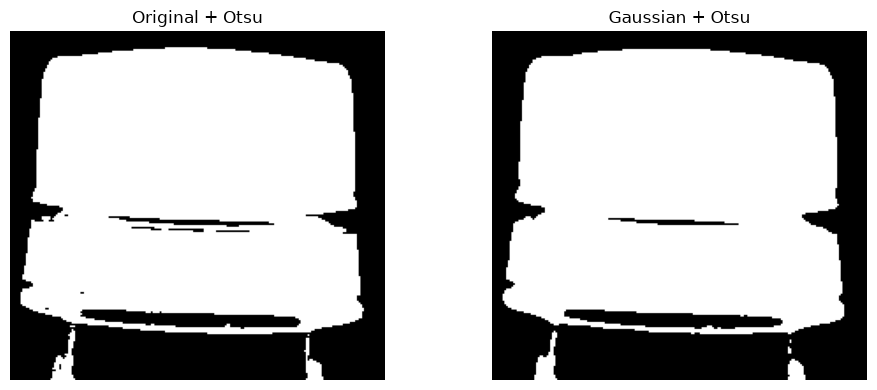

In [24]:
### STEP 24 — [Jupyter 추가] Binary 변화 확인
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(original_otsu, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Original + Otsu")
axes[1].imshow(gaussian_otsu, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("Gaussian + Otsu")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

**확인 질문:** Noise로 생긴 흰 점이 줄었나요? 동시에 병뚜껑 외곽의 흰색 영역도 줄거나 붙지는 않았나요?

---

# BLOCK 5 — CLAHE 후 Otsu 검증 (Process C)

### 의사코드

```text
1. CLAHE 설정을 만든다.
2. Gray 이미지에 CLAHE를 적용한다.
3. 전처리 전후 픽셀 분포와 이미지를 비교한다.
4. CLAHE 결과에 Otsu를 적용한다.
5. 첫 번째 Otsu와 분리 형태가 어떻게 달라졌는지 확인한다.
```

## STEP 25. CLAHE 설정을 만듭니다

In [25]:
### BLOCK 5 / STEP 25 — 원본 .py의 CLAHE 설정
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
print("CLAHE 객체 생성:", clahe is not None)

CLAHE 객체 생성: True


- `clipLimit=2.0`: 각 구역의 Histogram 증폭을 제한하는 설정입니다.
- `tileGridSize=(8, 8)`: 이미지를 8×8개의 구역으로 나누어 지역 대비를 처리합니다. **각 구역이 8×8픽셀이라는 뜻이 아닙니다.**

## STEP 26. Gray 이미지에 CLAHE를 적용합니다

In [26]:
### STEP 26 — 원본 .py의 지역 대비 개선
clahe_image = clahe.apply(gray)
print("CLAHE Shape:", clahe_image.shape)

CLAHE Shape: (198, 213)


`clahe.apply(gray)`는 Gray 배열을 입력받습니다. 이 예제에서 BGR 컬러 원본을 직접 입력하지 않는 이유를 이해합니다.

## STEP 27. CLAHE 전후 밝기값의 분산 정도를 비교합니다

In [27]:
### STEP 27 — [Jupyter 추가] 수치 비교
print("Gray min/max:", int(gray.min()), int(gray.max()))
print("CLAHE min/max:", int(clahe_image.min()), int(clahe_image.max()))
print("Gray 표준편차:", float(gray.std()))
print("CLAHE 표준편차:", float(clahe_image.std()))

Gray min/max: 80 162
CLAHE min/max: 62 211
Gray 표준편차: 25.163999835331257
CLAHE 표준편차: 34.1166657846044


표준편차가 커지는 것은 전체 밝기값이 더 퍼졌다는 한 가지 신호입니다. **CLAHE는 지역적인 명암을 조정하므로 전체 표준편차만으로 검사 품질을 평가할 수 없습니다.**

## STEP 28. CLAHE 전후 이미지를 눈으로 비교합니다

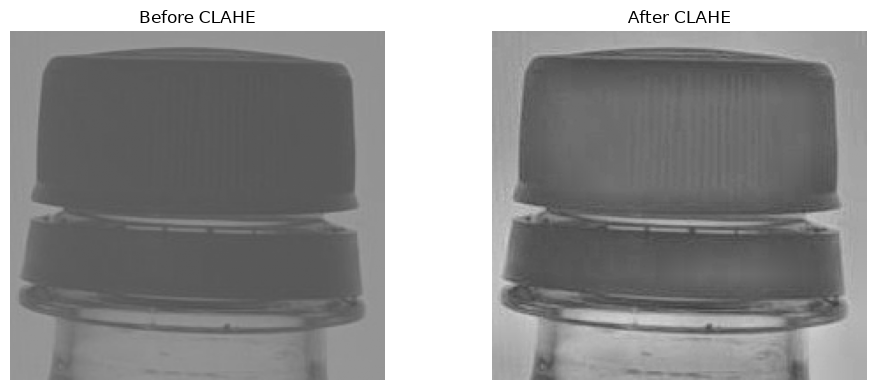

In [28]:
### STEP 28 — [Jupyter 추가] 지역 대비 시각화
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(gray, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Before CLAHE")
axes[1].imshow(clahe_image, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("After CLAHE")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

**확인 질문:** 병뚜껑과 배경의 밝기 차이가 더 뚜렷해졌나요? 원래 보이지 않던 Noise까지 두드러지지는 않았나요?

## STEP 29. CLAHE 결과에 Otsu를 적용합니다

In [29]:
### STEP 29 — 원본 .py의 세 번째 Otsu
clahe_value, clahe_otsu = cv2.threshold(
    clahe_image, 0, 255,
    cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU,
)
print("CLAHE Otsu Threshold:", clahe_value)

CLAHE Otsu Threshold: 132.0


이 단계가 세 번째 실험입니다. `gray`, `gaussian`, `clahe_image`라는 **서로 다른 세 입력**에 같은 Otsu 알고리즘을 적용한 것입니다.

## STEP 30. Original Otsu와 CLAHE Otsu를 비교합니다

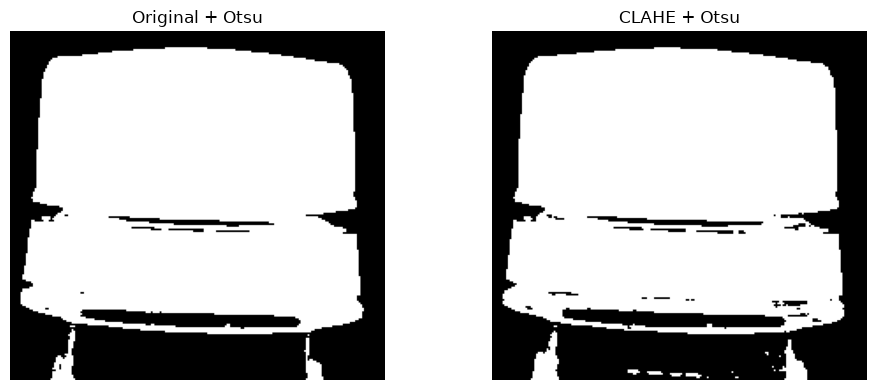

In [30]:
### STEP 30 — [Jupyter 추가] CLAHE의 Binary 영향
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(original_otsu, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Original + Otsu")
axes[1].imshow(clahe_otsu, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("CLAHE + Otsu")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

**확인 질문:** CLAHE를 사용하면 모든 조건에서 더 좋은가요? 실제로 분리된 객체의 외곽이나 배경의 흰색 Noise가 어떻게 변했는지 관찰합니다.

---

# BLOCK 6 — Otsu 결과 숫자와 이미지 비교 (Compare + Analysis)

### 의사코드

```text
1. 세 Otsu가 선택한 임계값을 출력한다.
2. Histogram에서 각 입력의 밝기 분포와 임계값 위치를 본다.
3. 각 Binary 이미지에서 흰색 픽셀의 비율을 계산한다.
4. 세 Binary 결과를 나란히 보고 왜 달라졌는지 생각한다.
5. 임계값이나 흰색 면적만으로 '좋아졌다'고 단정하지 않는다.
```

## STEP 31. 세 가지 임계값을 한 번에 출력합니다

In [31]:
### BLOCK 6 / STEP 31 — 원본 .py의 Otsu 결과 출력
print("Original Otsu:", original_value)
print("Gaussian Otsu:", gaussian_value)
print("CLAHE Otsu:", clahe_value)

Original Otsu: 118.0
Gaussian Otsu: 118.0
CLAHE Otsu: 132.0


세 값이 다르면 **전처리된 픽셀 분포가 달라져 Otsu의 선택도 달라질 수 있다**는 것을 보여줍니다. 숫자가 더 크다고 그 방법이 더 정확하다는 뜻은 아닙니다.

## STEP 32. 각 Histogram과 Otsu 임계값 위치를 확인합니다

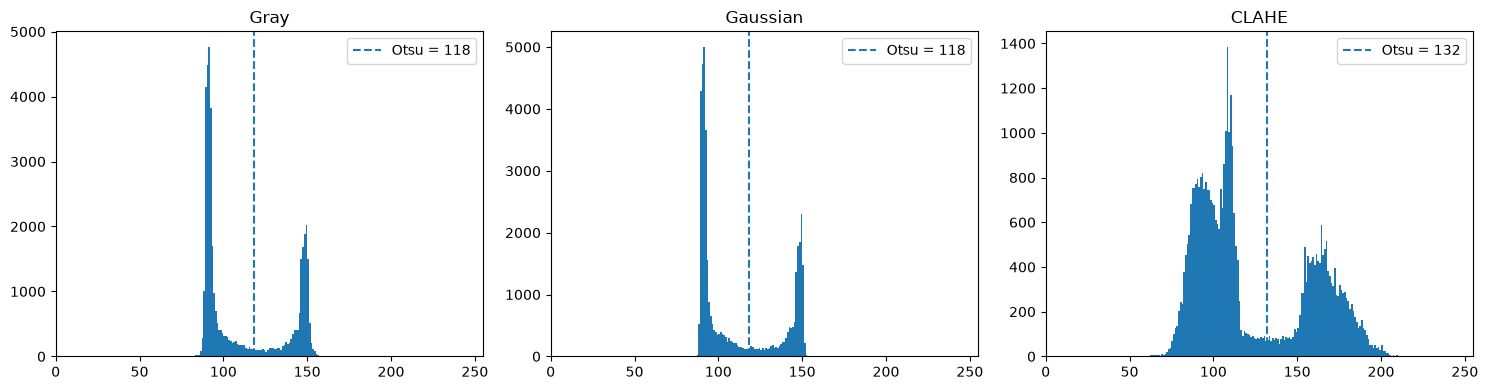

In [32]:
### STEP 32 — [Jupyter 추가] 임계값 위치 시각화
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
inputs = [gray, gaussian, clahe_image]
thresholds = [original_value, gaussian_value, clahe_value]
titles = ["Gray", "Gaussian", "CLAHE"]

for ax, src, t, title in zip(axes, inputs, thresholds, titles):
    ax.hist(src.ravel(), bins=256, range=(0, 256))
    ax.axvline(t, linestyle="--", label=f"Otsu = {t:.0f}")
    ax.set_title(title)
    ax.set_xlim(0, 255)
    ax.legend()
plt.tight_layout()
plt.show()

**Jupyter에서 추가한 분석 코드**입니다. 원본 16번 `.py`의 결과를 바꾸지 않습니다. 반드시 **각 Otsu에 실제 입력했던 이미지의 Histogram** 위에 임계값을 표시해야 합니다. 같은 Histogram 위에 세 임계값만 그리면 입력 조건을 잘못 설명하게 됩니다.

## STEP 33. 각 Binary 이미지의 흰색 픽셀 비율을 계산합니다

In [33]:
### STEP 33 — [Jupyter 추가] Binary 면적 기초 분석
original_ratio = np.count_nonzero(original_otsu) / original_otsu.size
gaussian_ratio = np.count_nonzero(gaussian_otsu) / gaussian_otsu.size
clahe_ratio = np.count_nonzero(clahe_otsu) / clahe_otsu.size

print(f"Original 흰색 비율: {original_ratio:.2%}")
print(f"Gaussian 흰색 비율: {gaussian_ratio:.2%}")
print(f"CLAHE 흰색 비율: {clahe_ratio:.2%}")

Original 흰색 비율: 64.92%
Gaussian 흰색 비율: 64.85%
CLAHE 흰색 비율: 64.63%


이 값은 Binary 이미지 전체에서 흰색으로 분류된 픽셀의 비율입니다. **병뚜껑의 실제 면적 비율과 반드시 같지는 않습니다.** 배경의 흰 점이나 연결된 오검출도 포함되기 때문입니다. 3일차 Contour 실습에서는 이런 영역을 추가로 구분하고 측정합니다.

## STEP 34. 세 가지 Otsu 결과를 한 화면에서 비교합니다

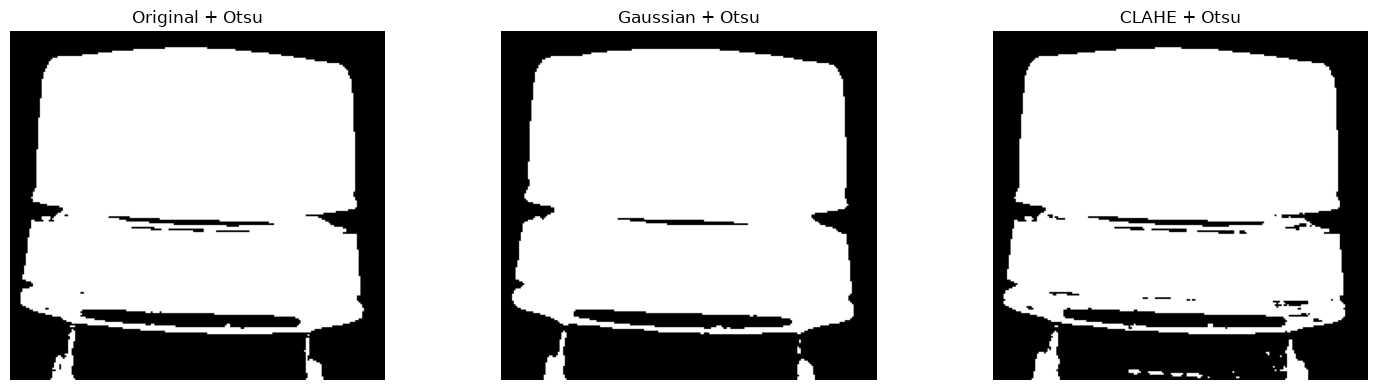

In [34]:
### STEP 34 — [Jupyter 추가] 최종 분리 형태 비교
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].imshow(original_otsu, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Original + Otsu")
axes[1].imshow(gaussian_otsu, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("Gaussian + Otsu")
axes[2].imshow(clahe_otsu, cmap="gray", vmin=0, vmax=255)
axes[2].set_title("CLAHE + Otsu")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

**관찰할 항목:** ① 병뚜껑 흰색 영역의 연속성, ② 작은 Noise, ③ 객체와 배경의 잘못된 연결, ④ 실제 윤곽의 손실 여부를 확인합니다.

> **실무적 주의:** 현재 이미지만으로 어느 방법이 더 정확하다고 객관적으로 입증하려면 별도의 기준 Mask, 추가 촬영 이미지 또는 이후 Contour 측정값 등이 필요합니다. 이 Notebook의 숫자·그림 비교는 **전처리의 영향과 후보를 관찰하는 단계**이며, 최종 검증은 3일차 측정·Rule 단계에서 이어집니다.

---

# BLOCK 7 — `make_view()` 함수를 작은 단계로 이해하기 (Display)

> 원본 `.py`에서는 아래 기능을 한 번에 수행하는 `make_view()` 함수를 만듭니다. Jupyter에서는 **Resize → 채널 수 통일 → 제목을 그리는 과정**을 먼저 각각 실행한 뒤, 마지막에 원본 함수를 정의합니다. 앞쪽 작은 셀은 **함수 동작 원리 검증을 위한 추가 실험**입니다.

### 의사코드

```text
1. 모든 비교 이미지를 같은 크기로 만들 준비를 한다.
2. Gray와 Binary에 맞는 Resize 방식의 차이를 확인한다.
3. Gray(1채널)를 BGR(3채널)로 바꾼다.
4. 검은 제목 영역과 흰색 글자를 그려 본다.
5. 위 과정을 make_view(source, title, is_binary)로 묶는다.
```

## STEP 35. 비교 이미지의 가로·세로 크기를 지정합니다

In [35]:
### BLOCK 7 / STEP 35 — 원본 .py의 출력 크기
view_size = (400, 300)
print("비교 타일 (Width, Height):", view_size)

비교 타일 (Width, Height): (400, 300)


OpenCV의 `cv2.resize()` 크기 인자는 **(가로, 세로)** 순서입니다. 결과 배열 `shape`는 (세로, 가로, 채널)이므로 순서가 다릅니다.

## STEP 36. Gray와 Binary를 각각 다른 방식으로 Resize합니다

In [36]:
### STEP 36 — [Jupyter 추가] 보간법 차이 확인
resized_gray = cv2.resize(gray, view_size, interpolation=cv2.INTER_AREA)
resized_binary = cv2.resize(original_otsu, view_size, interpolation=cv2.INTER_NEAREST)
print("Gray Resize Shape:", resized_gray.shape)
print("Binary Resize Shape:", resized_binary.shape)
print("Binary Resize 고유값:", np.unique(resized_binary))

Gray Resize Shape: (300, 400)
Binary Resize Shape: (300, 400)
Binary Resize 고유값: [  0 255]


원본 함수에서는 **일반 이미지에는 `INTER_AREA`, Binary에는 `INTER_NEAREST`**를 사용합니다. 이진 이미지를 부드럽게 보간하면 0·255 외의 회색 픽셀이 새로 생길 수 있으므로, 비교 화면에서는 최근접 보간을 사용합니다.

## STEP 37. Gray 타일을 BGR 3채널로 바꿉니다

In [37]:
### STEP 37 — [Jupyter 추가] 1채널 → 3채널
canvas = cv2.cvtColor(resized_gray, cv2.COLOR_GRAY2BGR)
print("변환 전 Shape:", resized_gray.shape)
print("변환 후 Shape:", canvas.shape)

변환 전 Shape: (300, 400)
변환 후 Shape: (300, 400, 3)


Gray 화면도 BGR 3채널로 통일하면 아래에서 `cv2.hconcat()`으로 이미지를 합칠 때 채널 개수 불일치 문제를 피할 수 있습니다. 세 채널 값이 같아서 화면상 회색 모습은 유지됩니다.

## STEP 38. 제목 표시용 검은 영역을 그립니다

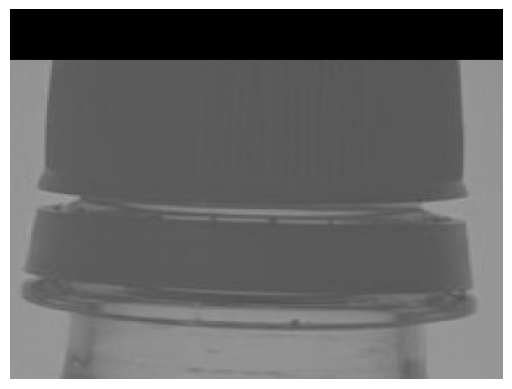

In [38]:
### STEP 38 — [Jupyter 추가] 타일 위쪽 제목 배경
cv2.rectangle(canvas, (0, 0), (view_size[0], 40), (0, 0, 0), -1)
plt.imshow(cv2.cvtColor(canvas, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

`-1`은 사각형 내부를 **채우는 설정**입니다. 검은 배경이 원본 타일의 위쪽 40픽셀을 가리므로, **출력용 화면은 분석할 원본 Binary 배열과 다릅니다.** 실제 픽셀 통계는 `original_otsu` 같은 원래 배열에서 계산해야 합니다.

## STEP 39. 제목을 흰색 글자로 표시합니다

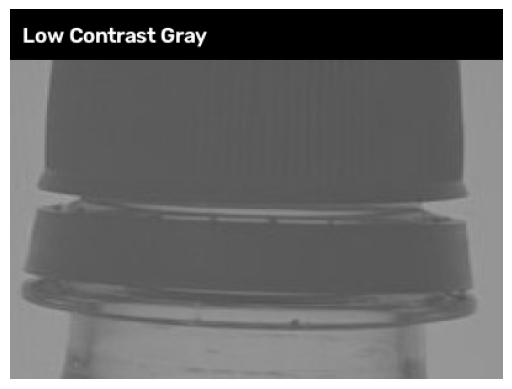

In [39]:
### STEP 39 — [Jupyter 추가] 텍스트 표시
cv2.putText(
    canvas, "Low Contrast Gray", (10, 27),
    cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 255, 255), 2,
)
plt.imshow(cv2.cvtColor(canvas, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

`(10, 27)`은 글자 기준 위치, `0.6`은 글자 크기, `(255,255,255)`는 흰색, `2`는 선 굵기입니다. **제목을 쓰는 코드는 시각화를 위한 것이며 Otsu 판정에는 영향을 주지 않습니다.**

## STEP 40. 원본의 `make_view()` 함수를 정의합니다

In [40]:
### STEP 40 — 원본 .py의 함수 전체
### 아래 STEP 36~39의 동작을 재사용 가능한 함수로 묶습니다.
def make_view(source, title, is_binary=False):
    if is_binary:
        interpolation = cv2.INTER_NEAREST
    else:
        interpolation = cv2.INTER_AREA

    resized = cv2.resize(source, view_size, interpolation=interpolation)

    if len(resized.shape) == 2:
        canvas = cv2.cvtColor(resized, cv2.COLOR_GRAY2BGR)
    else:
        canvas = resized.copy()

    cv2.rectangle(canvas, (0, 0), (view_size[0], 40), (0, 0, 0), -1)
    cv2.putText(
        canvas, title, (10, 27), cv2.FONT_HERSHEY_SIMPLEX,
        0.6, (255, 255, 255), 2,
    )
    return canvas

`def`를 실행하는 순간에는 이미지가 표시되지 않습니다. 이 셀은 **함수 이름과 처리 방법을 등록한 것**입니다. 다음 셀에서 실제로 호출하면 결과 배열이 만들어집니다.

## STEP 41. 함수가 400×300 BGR 타일을 만드는지 확인합니다

함수 출력 Shape: (300, 400, 3)


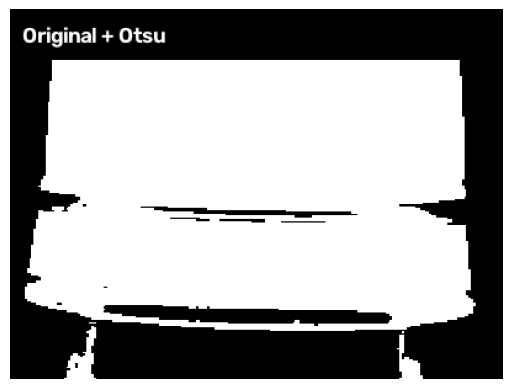

In [41]:
### STEP 41 — [Jupyter 추가] 함수 단위 테스트
sample_view = make_view(original_otsu, "Original + Otsu", is_binary=True)
print("함수 출력 Shape:", sample_view.shape)
plt.imshow(cv2.cvtColor(sample_view, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

**예상 Shape:** `(300, 400, 3)`. Binary인 `original_otsu`를 넣어도 함수 결과는 **제목이 표시된 BGR 3채널 이미지**입니다.

---

# BLOCK 8 — 2×2 비교 이미지 조립 (Compose)

### 의사코드

```text
1. 윗줄에 [Low Contrast Gray | Original + Otsu]를 놓는다.
2. 아랫줄에 [Gaussian + Otsu | CLAHE + Otsu]를 놓는다.
3. 두 줄을 위아래로 합쳐 하나의 비교 이미지를 만든다.
4. 최종 크기와 화면 구성을 확인한다.
```

## STEP 42. 윗줄 두 이미지를 가로로 합칩니다

In [42]:
### BLOCK 8 / STEP 42 — 원본 .py의 top
top = cv2.hconcat([
    make_view(gray, "Low Contrast Gray"),
    make_view(original_otsu, "Original + Otsu", is_binary=True),
])

위 코드는 위쪽 한 줄에 400×300 타일 두 장을 붙입니다. `cv2.hconcat`의 `h`는 **horizontal(가로)**의 의미입니다.

## STEP 43. 윗줄 결과를 확인합니다

Top Shape: (300, 800, 3)


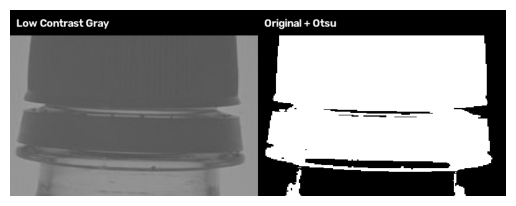

In [43]:
### STEP 43 — [Jupyter 추가] top만 확인
print("Top Shape:", top.shape)
plt.imshow(cv2.cvtColor(top, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

**예상 Shape:** `(300, 800, 3)`. 맨 왼쪽에 Gray가 있고 오른쪽에 Original + Otsu가 있는지 봅니다.

## STEP 44. 아랫줄 두 이미지를 가로로 합칩니다

In [44]:
### STEP 44 — 원본 .py의 bottom
bottom = cv2.hconcat([
    make_view(gaussian_otsu, "Gaussian + Otsu", is_binary=True),
    make_view(clahe_otsu, "CLAHE + Otsu", is_binary=True),
])

아랫줄은 Gaussian + Otsu와 CLAHE + Otsu 순서입니다. **두 이미지를 바꿔 넣으면 출력 제목과 해석 위치가 달라질 수 있으므로** 순서를 확인합니다.

## STEP 45. 아랫줄 결과를 확인합니다

Bottom Shape: (300, 800, 3)


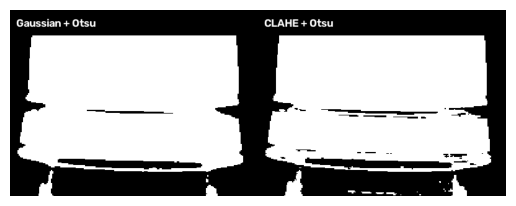

In [45]:
### STEP 45 — [Jupyter 추가] bottom만 확인
print("Bottom Shape:", bottom.shape)
plt.imshow(cv2.cvtColor(bottom, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

**예상 Shape:** `(300, 800, 3)`.

## STEP 46. 위아래 두 줄을 세로로 합칩니다

In [46]:
### STEP 46 — 원본 .py의 compare
compare = cv2.vconcat([top, bottom])
print("Compare Shape:", compare.shape)

Compare Shape: (600, 800, 3)


`cv2.vconcat`의 `v`는 **vertical(세로)**입니다. 두 줄을 붙였으므로 **예상 Shape은 `(600, 800, 3)`**입니다.

## STEP 47. 2×2 비교 화면을 실제로 확인합니다

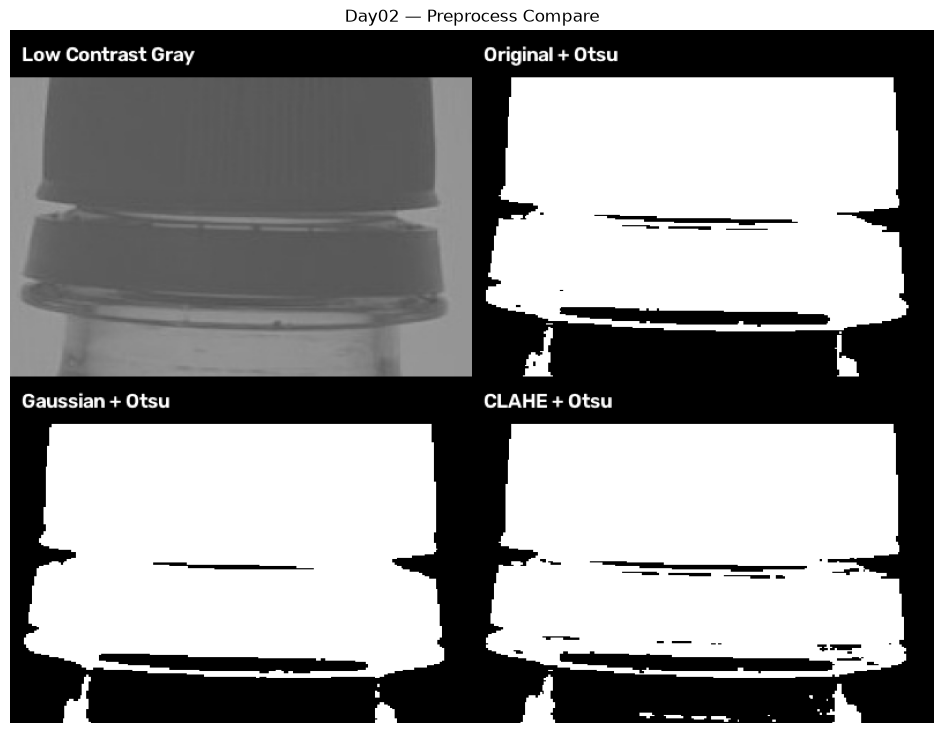

In [47]:
### STEP 47 — [Jupyter 추가] 최종 화면 미리보기
plt.figure(figsize=(12, 9))
plt.imshow(cv2.cvtColor(compare, cv2.COLOR_BGR2RGB))
plt.title("Day02 — Preprocess Compare")
plt.axis("off")
plt.show()

최종 배치는 다음과 같아야 합니다.

```text
┌────────────────────────┬────────────────────────┐
│ Low Contrast Gray      │ Original + Otsu        │
├────────────────────────┼────────────────────────┤
│ Gaussian + Otsu        │ CLAHE + Otsu           │
└────────────────────────┴────────────────────────┘
```

---

# BLOCK 9 — 결과 저장, QA 및 원본 `.py`와 연결 (Output + Integration)

### 의사코드

```text
1. 최종 저장 파일 경로를 정한다.
2. 비교 이미지를 저장한다.
3. 저장 함수의 성공 여부를 확인한다.
4. 저장된 이미지를 다시 읽어 크기를 확인한다.
5. Jupyter 결과와 원본 .py의 결과가 같은 입력·설정인지 확인한다.
6. 원본 .py를 전체 실행한다.
7. 3일차에서 동일 ROI와 Otsu 로직을 다시 사용함을 이해한다.
```

## STEP 48. 결과 파일 경로를 정합니다

In [48]:
### BLOCK 9 / STEP 48 — 원본 .py의 출력 경로
output_path = output_dir / "preprocess_compare.png"
print("저장할 파일:", output_path)

저장할 파일: /home/user1/ai_vision/subject9_machinevision/outputs/day02/compare/preprocess_compare.png


`output_dir`는 BLOCK 1에서 만든 폴더입니다. 이 셀은 결과 경로만 만들며 **아직 디스크에 저장하지 않습니다.**

## STEP 49. 비교 이미지를 저장합니다

In [49]:
### STEP 49 — 원본 .py의 저장 동작 + 저장 성공 여부 확인
saved = cv2.imwrite(str(output_path), compare)
print("저장 성공:", saved)
print("저장:", output_path)

저장 성공: True
저장: /home/user1/ai_vision/subject9_machinevision/outputs/day02/compare/preprocess_compare.png


원본 `.py`는 `cv2.imwrite()`를 호출하고 경로를 출력합니다. Notebook에서는 **저장 성공 여부를 따로 검증**하도록 반환값 `saved`를 받았습니다. `True`인지 확인합니다.

## STEP 50. 파일 존재 여부와 크기를 확인합니다

In [50]:
### STEP 50 — [Jupyter 추가] 결과 QA
print("결과 파일 존재:", output_path.is_file())
if not saved or not output_path.is_file():
    raise IOError(f"결과 저장 실패: {output_path}")

saved_compare = cv2.imread(str(output_path))
if saved_compare is None:
    raise IOError(f"저장 파일 읽기 실패: {output_path}")
print("저장 파일 Shape:", saved_compare.shape)

결과 파일 존재: True
저장 파일 Shape: (600, 800, 3)


**예상 Shape:** `(600, 800, 3)`. PNG는 이 예제의 BGR 픽셀값을 손실 없이 저장하므로, 저장 이미지와 메모리 속 `compare`를 추가 비교할 수도 있습니다.

## STEP 51. 저장 전·후 이미지가 같은지 확인합니다

In [51]:
### STEP 51 — [Jupyter 추가] 저장 결과 재검증
print("저장 전후 Shape 같음:", saved_compare.shape == compare.shape)
print("저장 전후 픽셀 같음:", np.array_equal(saved_compare, compare))

저장 전후 Shape 같음: True
저장 전후 픽셀 같음: True


같은 PNG 파일을 쓰고 읽었다면 일반적으로 두 결과 모두 `True`여야 합니다. 픽셀 동일 여부를 확인하는 것은 **저장이 정상적으로 이루어졌는지**에 대한 검증이지, 어느 전처리가 검사 성능이 좋은지에 대한 검증은 아닙니다.

## STEP 52. 원본 `.py`와 Jupyter 추가 코드를 구분합니다

| 항목 | 기존 `16_preprocess_compare.py` | 이번 Jupyter 코드 리뷰 |
|---|---|---|
| 기준 이미지 읽기·없으면 생성 | 있음 | 조건 실행 여부 및 픽셀 구조 확인 |
| Gray 변환 | 있음 | 픽셀별 가중치 근사 계산·Histogram **추가** |
| Original / Gaussian / CLAHE + Otsu | 있음 | 각 단계 화면·픽셀값·차이 비교 **추가** |
| Otsu 임계값 출력 | 있음 | 각 입력 Histogram 위 임계값 표시 **추가** |
| 흰색 픽셀 비율 | 없음 | 학습용 수치 비교 **추가** |
| `make_view()` | 있음 | 내부 동작을 분해해 실행·검증 |
| `hconcat()`·`vconcat()` | 있음 | 각 중간 결과 화면 확인 **추가** |
| PNG 저장 | 있음 | 저장 성공·재읽기·픽셀 동일성 **추가** |

**중요:** Notebook에서 실험한 Gaussian Kernel, CLAHE 값 등을 수정해도 **원본 `.py`는 자동 변경되지 않습니다.** 두 파일의 결과를 같게 만들고 싶다면 최종 선택한 파라미터를 원본 `.py`에도 반영해야 합니다.

## STEP 53. 원본 `.py`를 전체 실행합니다

이 STEP은 **선택 실행**입니다. 앞의 Jupyter 코드 검증을 끝낸 뒤, 원본 `src/16_preprocess_compare.py`도 같은 데이터와 설정으로 실행되는지 확인합니다. 원본 파일은 Jupyter와 달리 **현재 작업 폴더를 기준으로 상대경로를 사용**하므로 프로젝트 루트에서 실행해야 합니다.

VS Code **WSL2 터미널**에서:

```bash
cd ~/ai_vision/subject9_machinevision
python src/16_preprocess_compare.py
```

Jupyter에서 별도 프로세스로 실행할 경우에는 아래 셀을 **필요할 때만** 실행합니다.

In [52]:
# STEP 53 — [선택] 원본 .py 실행: 작업 폴더를 명시
import subprocess
source_script = project_root / "src/16_preprocess_compare.py"
if source_script.is_file():
    subprocess.run(
        [sys.executable, str(source_script)],
        cwd=str(project_root),  # 원본의 상대경로 문제 예방
        check=True,
    )
    print("원본 .py 실행 완료:", source_script)
else:
    print("원본 .py가 없어 선택 실행을 건너뜁니다:", source_script)

Original Otsu: 118.0
Gaussian Otsu: 118.0
CLAHE Otsu: 132.0
저장: outputs/day02/compare/preprocess_compare.png
원본 .py 실행 완료: /home/user1/ai_vision/subject9_machinevision/src/16_preprocess_compare.py


**주의:** 이 원본 스크립트와 Notebook은 **같은 `preprocess_compare.png`를 저장**합니다. 나중에 실행한 쪽이 기존 결과를 덮어쓸 수 있습니다. 파라미터를 변경한 실험 결과를 남기려면 미리 다른 파일명으로 저장하세요.

## STEP 54. 직접 바꾸어 보는 작은 코드 리뷰 Challenge

| 실험 | 수정할 곳 | 예측해 볼 변화 | 재실행할 범위 |
|---|---|---|---|
| A | STEP 20의 `(5, 5)`를 `(3, 3)`으로 | Blur와 Otsu 결과가 얼마나 달라질까? | STEP 20~24, 31~34, 42~51 |
| B | STEP 20의 `(5, 5)`를 `(9, 9)`로 | 작은 Noise와 병뚜껑 경계가 함께 흐려질까? | STEP 20~24, 31~34, 42~51 |
| C | STEP 25의 `clipLimit=2.0`을 `4.0`으로 | 대비뿐 아니라 Noise도 강조될까? | STEP 25~30, 31~34, 42~51 |
| D | STEP 25의 `tileGridSize=(8, 8)`을 `(4, 4)`로 | 지역 대비와 Binary 영역이 달라질까? | STEP 25~30, 31~34, 42~51 |
| E | STEP 15·16의 `THRESH_BINARY_INV` 의미를 확인 | 어두운 객체가 흰색이 되는 원리를 설명할 수 있을까? | STEP 15~19만 별도 관찰 후 원래 설정 유지 |

> **재실행 범위 안내:** STEP 42~51을 재실행할 때 STEP 40의 `make_view()` 함수는 이미 정의되어 있으면 다시 실행할 필요가 없습니다. 다만 `view_size`나 함수 본문을 바꿨다면 STEP 35·40도 먼저 실행하세요. Challenge가 끝나면 원래 설정인 **Gaussian 5×5, CLAHE 2.0 / 8×8, Binary INV + Otsu**로 돌린 후 Kernel을 재시작하고 전체 셀을 다시 실행합니다.

## STEP 55. 핵심 코드 리뷰 질문

1. `image is None` 조건문은 어떤 경우 실행되나요?
2. `convertScaleAbs(alpha=0.35, beta=80)`에서 `alpha`와 `beta`의 역할은 무엇인가요?
3. 컬러 이미지 `image.shape`와 Gray 이미지 `gray.shape`는 어떻게 다른가요?
4. `cv2.threshold()`의 첫 번째 반환값과 두 번째 반환값은 각각 무엇인가요?
5. 왜 `THRESH_BINARY_INV`를 사용했나요? 모든 이미지에서 항상 맞는 방향인가요?
6. Gaussian의 `(5, 5)`를 크게 바꾸면 Noise와 객체 경계는 어떻게 될까요?
7. CLAHE의 `tileGridSize=(8, 8)`은 8×8 **픽셀**을 뜻하나요?
8. 세 Otsu 임계값 중 가장 큰 값이 가장 좋은 전처리를 뜻하나요?
9. `np.count_nonzero(binary)/binary.size`가 병뚜껑의 정확한 면적 비율이라고 할 수 없는 이유는 무엇인가요?
10. Binary를 Resize할 때 `INTER_NEAREST`를 사용하는 이유는 무엇인가요?
11. 함수 `make_view()`가 반환한 이미지가 왜 3채널인가요?
12. `cv2.hconcat()`과 `cv2.vconcat()`은 어떤 방향으로 이미지를 합치나요?
13. 왜 화면 제목이 덧그려진 `compare`에서 병뚜껑의 픽셀값을 분석하면 안 되나요?
14. Notebook에서 바꾼 CLAHE 설정이 원본 `.py`에 자동 반영되지 않는 이유는 무엇인가요?
15. 3일차가 2일차 `preprocess_compare.png` 대신 ROI 기준 이미지를 다시 읽는 이유는 무엇인가요?

---

## 실행 점검 체크리스트

- [ ] STEP 1: `sys.executable`이 수업에 사용 중인 Jupyter 커널의 Python 경로인가?
- [ ] STEP 2: `project_root`가 `None`이 아니며 실제 프로젝트 위치인가?
- [ ] STEP 3: 기준 ROI는 존재하며, 저대비 이미지의 절대경로가 VS Code 탐색기와 일치하는가?
- [ ] STEP 5: 기존 `low_contrast.jpg`를 정상적으로 읽거나, 없으면 STEP 6~7에서 생성했는가?
- [ ] STEP 8: `image.shape`가 `(높이, 너비, 3)`이고 dtype이 `uint8`인가?
- [ ] STEP 17: Binary 픽셀값이 0과 255로 확인되는가?
- [ ] STEP 23·29: Gaussian 및 CLAHE 결과에도 각각 Otsu를 적용했는가?
- [ ] STEP 33: 흰색 비율은 측정했지만 검사 정확도로 오해하지 않았는가?
- [ ] STEP 41·46: 비교 타일 `(300, 400, 3)`, 전체 비교 화면 `(600, 800, 3)`인가?
- [ ] STEP 49~51: PNG 저장 성공과 저장 전후 픽셀 동일성을 확인했는가?

**결과 해석 유의사항:** 이번 실습의 `Original + Otsu`에서 Original은 촬영한 `cap_on_reference.jpg` 그대로가 아니라, **`low_contrast.jpg`를 Gray로 변환한 뒤 추가 전처리 없이** Otsu를 적용한 경우입니다. 세 Otsu의 임계값이나 전체 흰색 픽셀 비율만으로 실제 병뚜껑 검사 성능을 확정하지 않습니다.

---

## 최종 정리 — 1일차·2일차·3일차는 어떻게 연결되나요?

```text
[1일차]
실시간 Frame에서 검사할 ROI 지정
  └─ cap_on.jpg / cap_off.jpg 확보
           ↓
[2일차]
ROI 기준 이미지를 준비하고 영상 품질을 비교
  ├─ Gray → Otsu
  ├─ Gray → Gaussian → Otsu
  └─ Gray → CLAHE → Otsu
           ↓
전처리별 Binary 결과와 픽셀값을 비교
           ↓
[3일차]
동일한 ROI 기준 이미지로 다시 시작
  → Gray → Otsu → Morphology → Contour
  → Area·Count·BBox·Center 측정
  → cap_on / cap_off 비교 → Rule → OK / NG
```

2일차의 출력 `preprocess_compare.png`는 **어느 전처리 방법이 분리에 어떤 영향을 미치는지 보여주는 비교 자료**입니다. 이 파일을 3일차에 그대로 넣어 객체를 측정하는 것은 아닙니다. 3일차는 **같은 ROI 기준 이미지에서 Otsu를 다시 실행한 후** Morphology·Contour를 통해 실제 특징값을 계산합니다.

**가장 중요한 학습 성과:** 학생이 `cv2.threshold()`, `cv2.GaussianBlur()`, `clahe.apply()`를 외우는 것보다 **각 함수의 입력 배열이 무엇이고, 출력 픽셀값이 어떻게 변하며, 다음 단계가 왜 필요한지** 설명할 수 있어야 합니다.

2일차 — Image Enhancement와 검사 이미지 품질 개선 다시 돌아가기